<a href="https://colab.research.google.com/github/jungyouha/cds230/blob/main/lab7/svm_census_income.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SVM on the Census Income (Adult) Dataset

**Dataset:** UCI Machine Learning Repository — *Census Income* / *Adult* (1996), extracted from the 1994 US Census.
48,842 adults described by 14 features (age, education, occupation, hours worked per week, …).

**Goal:** Train a Support Vector Machine to predict whether a person earns **more than $50K per year**.

**What's different from the digits data:**
- Many features are **text categories** (e.g. occupation = "Sales") → must be converted to numbers (one-hot encoding).
- Some values are **missing** (shown as `?`).
- The classes are **unbalanced** (only about 1 in 4 people earn >$50K).
- 32,561 training rows is large for a kernel SVM, so we use a **linear SVM on all data** and an
  **RBF SVM on a random sample**.

**Before running:** upload `adult.data` and `adult.test` with the 📁 folder icon on the left.
(If you skip the upload, the next cell downloads them from UCI automatically.)

## Step 0 — Load the data

In [10]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)

base_url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/adult/'
cols = ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status',
        'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss',
        'hours-per-week', 'native-country', 'income']

def load(name, skiprows=0):
    path = name if os.path.exists(name) else base_url + name
    return pd.read_csv(path, header=None, names=cols, skiprows=skiprows,
                       skipinitialspace=True, na_values='?')

train = load('adult.data')
test  = load('adult.test', skiprows=1)        # first line of adult.test is a comment

# adult.test writes labels as '>50K.' / '<=50K.' (with a period) — remove it
for d in (train, test):
    d['income'] = d['income'].str.replace('.', '', regex=False).str.strip()
    d.dropna(subset=['income'], inplace=True)

print('Training set:', train.shape)   # expect (32561, 15)
print('Test set    :', test.shape)    # expect (16281, 15)
print()
print('Income classes (training):')
print(train['income'].value_counts(normalize=True).round(3).to_string())
print()
print('Missing values per column (training):')
print(train.isna().sum()[train.isna().sum() > 0].to_string())
train.head()

Training set: (32561, 15)
Test set    : (16281, 15)

Income classes (training):
income
<=50K    0.759
>50K     0.241

Missing values per column (training):
workclass         1836
occupation        1843
native-country     583


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


## Step 1 — Prepare the features
- **Drop `fnlwgt`**: it is a census sampling weight (how many people this row represents), not a trait of the person.
- **Drop `education`**: it is the same information as `education-num` (e.g. "Bachelors" = 13).
- **Missing values** in categorical columns become their own category `"Unknown"`.
- **Numeric columns** → standardized (mean 0, std 1). SVM measures distances, so scale matters.
- **Categorical columns** → one-hot encoded (one 0/1 column per category).
- Target: `1` if income >$50K, else `0`.

In [11]:
numeric_cols = ['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
categorical_cols = ['workclass', 'marital-status', 'occupation', 'relationship',
                    'race', 'sex', 'native-country']

def split(d):
    X = d[numeric_cols + categorical_cols].copy()
    X[categorical_cols] = X[categorical_cols].fillna('Unknown')
    y = (d['income'] == '>50K').astype(int).values
    return X, y

X_train, y_train = split(train)
X_test,  y_test  = split(test)

preprocess = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
])

n_cols = preprocess.fit(X_train).transform(X_train.head()).shape[1]
print(f'14 original features -> {n_cols} model columns after one-hot encoding')

baseline = 1 - y_test.mean()
print(f'Baseline: always guessing "<=50K" would already be {baseline:.1%} accurate on the test set.')
print('So accuracy alone is not enough — we also check recall for the >50K group.')

14 original features -> 91 model columns after one-hot encoding
Baseline: always guessing "<=50K" would already be 76.4% accurate on the test set.
So accuracy alone is not enough — we also check recall for the >50K group.


## Step 2 — Linear SVM on all 32,561 training rows
A linear SVM is fast on large data. We compare the default model with `class_weight='balanced'`,
which tells the SVM to care equally about both classes (otherwise it can lean toward the majority "<=50K").

In [12]:
linear_models = {}
for cw in [None, 'balanced']:
    start = time.time()
    model = Pipeline([('prep', preprocess),
                      ('svm', LinearSVC(C=1.0, class_weight=cw, max_iter=10000))])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    linear_models[cw] = model
    print(f'class_weight={str(cw):9s}  accuracy={accuracy_score(y_test, pred):.2%}  '
          f'recall(>50K)={tp / (tp + fn):.2%}  precision(>50K)={tp / (tp + fp):.2%}  '
          f'time={time.time() - start:.1f}s')

class_weight=None       accuracy=85.44%  recall(>50K)=59.44%  precision(>50K)=73.84%  time=0.6s
class_weight=balanced   accuracy=80.46%  recall(>50K)=85.13%  precision(>50K)=55.65%  time=0.7s


## Step 3 — RBF (kernel) SVM, tuned on a sample
Kernel SVM training time grows roughly with the *square* of the number of rows, so we tune `C` and `gamma`
with 3-fold cross-validation on a random 5,000-row sample, then train the final model on 15,000 rows.

In [13]:
rng = np.random.RandomState(42)
tune_idx = rng.choice(len(X_train), 5000, replace=False)

rbf = Pipeline([('prep', preprocess), ('svm', SVC(kernel='rbf'))])
param_grid = {'svm__C': [0.1, 1, 10], 'svm__gamma': ['scale', 0.01, 0.1]}

start = time.time()
grid = GridSearchCV(rbf, param_grid, cv=3, n_jobs=-1)
grid.fit(X_train.iloc[tune_idx], y_train[tune_idx])
print('Best parameters :', grid.best_params_)
print('Best CV accuracy: {:.2%}   (tuning time {:.0f}s)'.format(grid.best_score_, time.time() - start))

scores = pd.DataFrame(grid.cv_results_)[['param_svm__C', 'param_svm__gamma', 'mean_test_score']]
print()
print(scores.pivot(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score').round(4))

Best parameters : {'svm__C': 1, 'svm__gamma': 0.1}
Best CV accuracy: 86.08%   (tuning time 18s)

param_svm__gamma    0.01     0.1   scale
param_svm__C                            
0.1               0.8014  0.8432  0.8434
1.0               0.8510  0.8608  0.8602
10.0              0.8562  0.8520  0.8538


In [14]:
final_idx = rng.choice(len(X_train), 15000, replace=False)
start = time.time()
best_rbf = grid.best_estimator_.fit(X_train.iloc[final_idx], y_train[final_idx])
y_pred = best_rbf.predict(X_test)

print('RBF SVM trained on 15,000 rows in {:.0f}s'.format(time.time() - start))
print('Support vectors used:', best_rbf.named_steps['svm'].n_support_.sum())
print()
print('Test accuracy: {:.2%}'.format(accuracy_score(y_test, y_pred)))
print()
print(classification_report(y_test, y_pred, target_names=['<=50K', '>50K'], digits=3))

RBF SVM trained on 15,000 rows in 13s
Support vectors used: 5103

Test accuracy: 85.64%

              precision    recall  f1-score   support

       <=50K      0.880     0.940     0.909     12435
        >50K      0.751     0.587     0.659      3846

    accuracy                          0.856     16281
   macro avg      0.816     0.763     0.784     16281
weighted avg      0.850     0.856     0.850     16281



## Confusion matrix (RBF SVM)

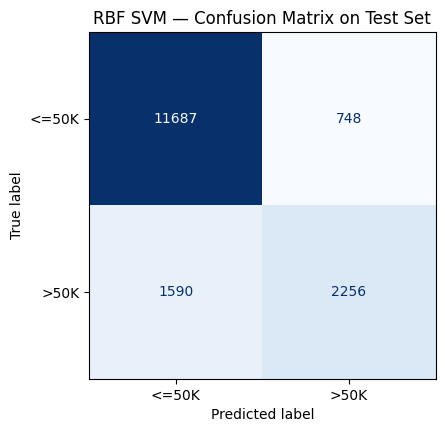

In [15]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=['<=50K', '>50K']).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('RBF SVM — Confusion Matrix on Test Set')
plt.savefig('svm_census_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

## Which features push someone toward >$50K? (Linear SVM weights)
A linear SVM gives each column a weight: positive → pushes toward >$50K, negative → toward <=$50K.
(The RBF model has no simple weights, which is the price of its curved boundary.)

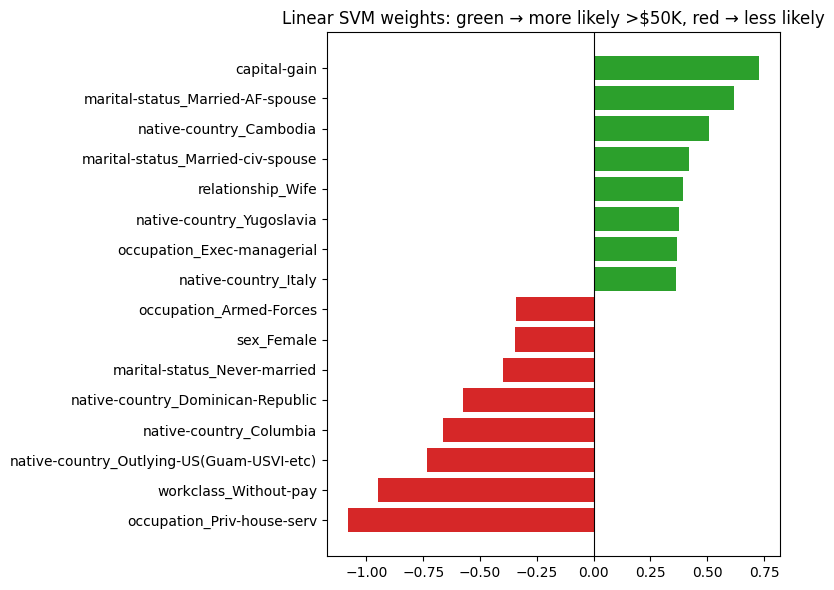

In [16]:
lin = linear_models['balanced']
names = lin.named_steps['prep'].get_feature_names_out()
names = [n.replace('num__', '').replace('cat__', '') for n in names]
weights = pd.Series(lin.named_steps['svm'].coef_[0], index=names).sort_values()

top = pd.concat([weights.head(8), weights.tail(8)])
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=['tab:red' if v < 0 else 'tab:green' for v in top.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Linear SVM weights: green → more likely >$50K, red → less likely')
plt.tight_layout()
plt.savefig('svm_census_weights.png', dpi=150)
plt.show()

## Model comparison

In [17]:
rows = []
for label, m in [('Linear SVM (default)', linear_models[None]),
                 ('Linear SVM (balanced)', linear_models['balanced']),
                 ('RBF SVM (tuned, 15k rows)', best_rbf)]:
    p = m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append([label, accuracy_score(y_test, p), tp / (tp + fn), tp / (tp + fp)])
comparison = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'Recall (>50K)', 'Precision (>50K)'])
comparison.loc[len(comparison)] = ['Baseline: always "<=50K"', baseline, 0.0, np.nan]
print(comparison.round(3).to_string(index=False))

                    Model  Accuracy  Recall (>50K)  Precision (>50K)
     Linear SVM (default)     0.854          0.594             0.738
    Linear SVM (balanced)     0.805          0.851             0.557
RBF SVM (tuned, 15k rows)     0.856          0.587             0.751
 Baseline: always "<=50K"     0.764          0.000               NaN


## Automatic plain-language summary (uses your actual numbers)

In [18]:
best_row = comparison.iloc[:3].sort_values('Accuracy', ascending=False).iloc[0]
bal = comparison.iloc[1]
print(f'''
- We trained SVMs on {len(y_train):,} adults from the 1994 US Census and tested on {len(y_test):,} others.
- Only {y_test.mean():.0%} of people in the test set earn more than $50K, so guessing "<=50K" for everyone
  is already {baseline:.0%} accurate.
- The best model ({best_row.Model}) was {best_row.Accuracy:.1%} accurate.
- The balanced linear SVM found {bal["Recall (>50K)"]:.0%} of the high earners
  (when it predicts >$50K it is right {bal["Precision (>50K)"]:.0%} of the time).
- Strongest signs of >$50K: {", ".join(weights.tail(3).index[::-1])}.
- Strongest signs of <=$50K: {", ".join(weights.head(3).index)}.
''')


- We trained SVMs on 32,561 adults from the 1994 US Census and tested on 16,281 others.
- Only 24% of people in the test set earn more than $50K, so guessing "<=50K" for everyone
  is already 76% accurate.
- The best model (RBF SVM (tuned, 15k rows)) was 85.6% accurate.
- The balanced linear SVM found 85% of the high earners
  (when it predicts >$50K it is right 56% of the time).
- Strongest signs of >$50K: capital-gain, marital-status_Married-AF-spouse, native-country_Cambodia.
- Strongest signs of <=$50K: occupation_Priv-house-serv, workclass_Without-pay, native-country_Outlying-US(Guam-USVI-etc).



I used the Adult Income dataset from the 1994 US Census to predict whether a person earns more than $50,000 per year. I trained SVM models using 32,561 people and tested them on 16,281 others. The best model was RBF SVM, which achieved 85.6% accuracy. The results showed that capital gains and marital status were important factors related to income predictions. However, the model was not always accurate, especially when identifying higher-income people. This shows that SVM can help predict income levels, but it still has some limitations.